# 03 - Categorical Distributions and Statistical Questions

**Project:** German Credit Risk
**Dataset:** `data/german_credit_data.csv`
**Author:** Divya Akbari

**Goal of this notebook**
1. Inspect the distribution of every categorical column.
2. Compare the bad-risk rate across the groups of each column.
3. Identify possible statistical questions for further analysis.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 120)

df = pd.read_csv('data/german_credit_data.csv')
df = df.drop(columns=['Unnamed: 0'])   # row number only, not real data
print(df.shape)

(1000, 10)


## 1. Categorical columns

| Column | Meaning |
|---|---|
| Sex | male or female |
| Job | Skill level: 0 = unskilled and non-resident, 1 = unskilled and resident, 2 = skilled, 3 = highly skilled |
| Housing | own, rent or free |
| Saving accounts | Savings balance: little, moderate, quite rich or rich |
| Checking account | Checking balance: little, moderate or rich |
| Purpose | What the loan is for |

`Job` is stored as a number but it is a **category**, so it is treated as categorical.
`Saving accounts` (183 missing) and `Checking account` (394 missing) are the only columns with missing values.
They are kept as a separate **"missing"** group, because a missing value may mean the customer has no account of that type.

In [2]:
print(df[['Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']].isna().sum())

Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Purpose               0
dtype: int64


## 2. Categorical variable distributions

In [3]:
cat_cols = ['Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

# Show missing values as their own group
cat_df = df[cat_cols + ['Risk']].copy()
for col in ['Saving accounts', 'Checking account']:
    cat_df[col] = cat_df[col].fillna('missing')

def category_table(col):
    table = pd.crosstab(cat_df[col], cat_df['Risk'])
    table['Total'] = table['good'] + table['bad']
    table['Share (%)'] = (table['Total'] / len(cat_df) * 100).round(1)
    table['Bad rate (%)'] = (table['bad'] / table['Total'] * 100).round(1)
    return table[['Total', 'Share (%)', 'good', 'bad', 'Bad rate (%)']].sort_values('Total', ascending=False)

In [4]:
for col in cat_cols:
    print('=' * 60)
    print(col)
    print('=' * 60)
    print(category_table(col))
    print()

Sex
Risk    Total  Share (%)  good  bad  Bad rate (%)
Sex                                              
male      690       69.0   499  191          27.7
female    310       31.0   201  109          35.2

Job
Risk  Total  Share (%)  good  bad  Bad rate (%)
Job                                            
2       630       63.0   444  186          29.5
1       200       20.0   144   56          28.0
3       148       14.8    97   51          34.5
0        22        2.2    15    7          31.8

Housing
Risk     Total  Share (%)  good  bad  Bad rate (%)
Housing                                           
own        713       71.3   527  186          26.1
rent       179       17.9   109   70          39.1
free       108       10.8    64   44          40.7

Saving accounts
Risk             Total  Share (%)  good  bad  Bad rate (%)
Saving accounts                                           
little             603       60.3   386  217          36.0
missing            183       18.3   151   32 

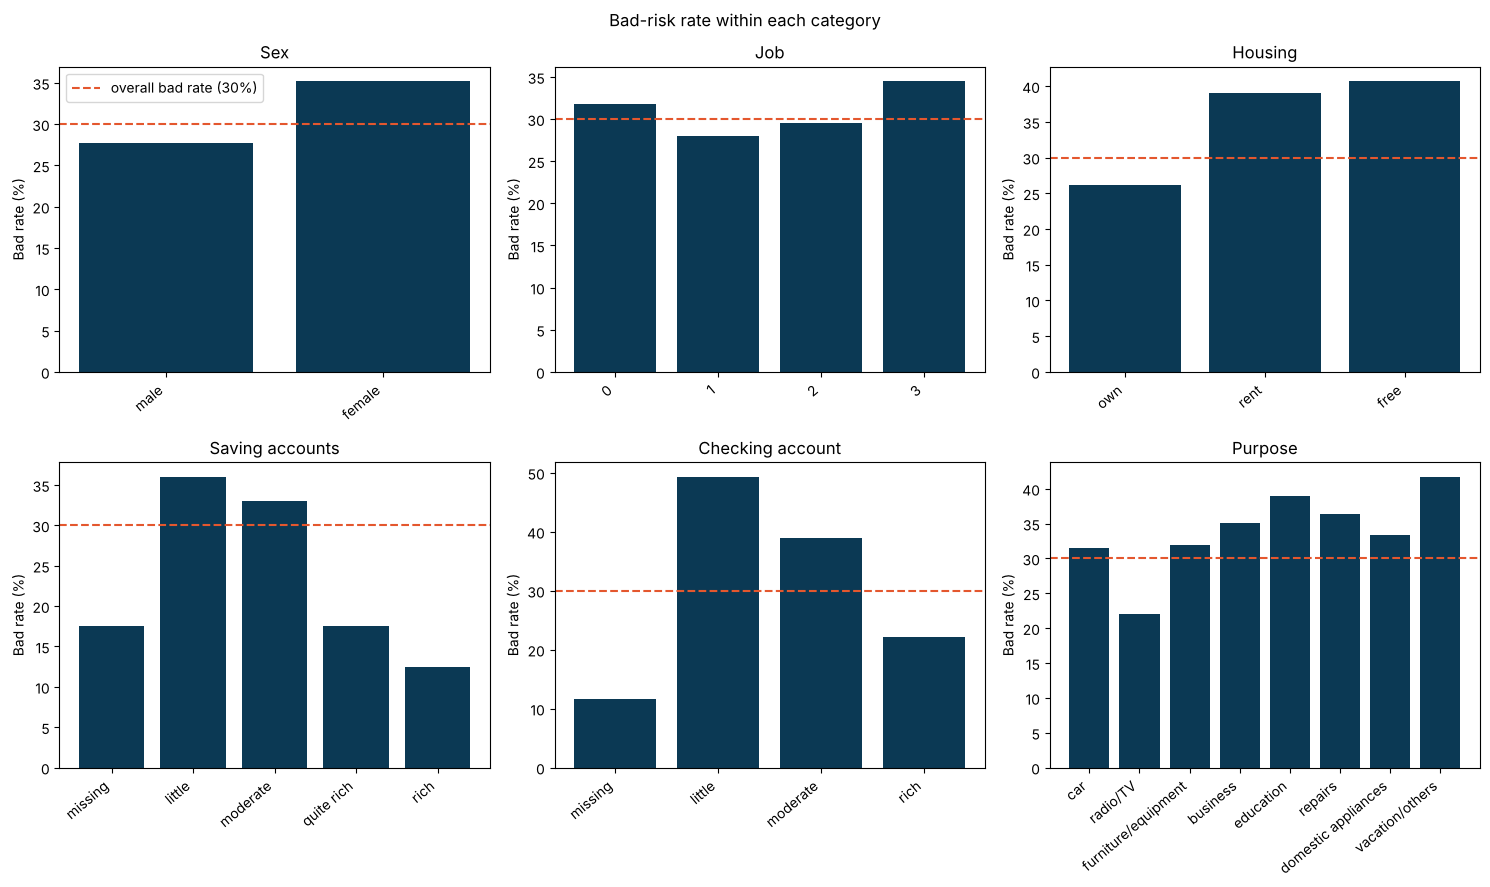

In [5]:
# Show ordered categories (job level, account balance) in their natural order
chart_order = {
    'Job': [0, 1, 2, 3],
    'Saving accounts': ['missing', 'little', 'moderate', 'quite rich', 'rich'],
    'Checking account': ['missing', 'little', 'moderate', 'rich'],
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flatten(), cat_cols):
    table = category_table(col)
    if col in chart_order:
        table = table.loc[chart_order[col]]
    ax.bar(table.index.astype(str), table['Bad rate (%)'], color='#0B3954')
    ax.axhline(30, color='#E4572E', linestyle='--', label='overall bad rate (30%)')
    ax.set_title(col)
    ax.set_ylabel('Bad rate (%)')
    plt.setp(ax.get_xticklabels(), rotation=40, ha='right')
axes[0, 0].legend()
plt.suptitle('Bad-risk rate within each category')
plt.tight_layout()
plt.show()

**What the distributions show**
- **Checking account** shows the biggest differences: 49.3% of customers with a "little" balance are bad risk,
  compared with only 11.7% of customers with no recorded checking account.
- **Saving accounts:** the bad rate falls as savings rise, from 36.0% ("little") to 12.5% ("rich").
- **Housing:** home owners are lower risk (26.1%) than renters (39.1%) and people living for free (40.7%).
- **Purpose:** radio/TV loans are lowest risk (22.1%); education (39.0%) and vacation/others (41.7%) are higher.
  Some purposes have very few customers (12 to 22), so their rates are less reliable.
- **Sex:** women have a higher bad rate (35.2%) than men (27.7%); 69% of applicants are men.
- **Job:** differences are small (28.0% to 34.5%); only 22 customers are in job level 0.

## 3. Possible statistical questions for further analysis

| # | Question | Suggested test |
|---|---|---|
| 1 | Is checking-account status associated with credit risk? | Chi-square test of independence |
| 2 | Is saving-account level associated with credit risk, and does risk fall as savings rise? | Chi-square test; chi-square test for trend |
| 3 | Do bad-risk customers borrow larger amounts than good-risk customers? | Mann-Whitney U test (amounts are skewed) |
| 4 | Do bad-risk customers have longer loan durations? | Mann-Whitney U test |
| 5 | Are younger customers more likely to be bad risk? | Mann-Whitney U test; bad rate by age group |
| 6 | Does housing type (own, rent, free) affect credit risk? | Chi-square test |
| 7 | Is the higher bad rate for women still there after accounting for age, loan amount and duration? | Logistic regression |
| 8 | Does loan purpose affect credit risk once small groups are combined? | Chi-square test (merge groups with fewer than 30 customers) |
| 9 | Do missing checking or saving values carry information about risk? | Chi-square test, missing vs not missing |
| 10 | Does the effect of credit amount on risk depend on loan duration? | Logistic regression with an interaction term |

## 4. Quick checks

In [6]:
checks = {
    'Dataset has 1,000 rows': len(df) == 1000,
    'No duplicate rows': df.duplicated().sum() == 0,
    'Only Saving and Checking accounts have missing values':
        set(df.columns[df.isna().any()]) == {'Saving accounts', 'Checking account'},
    'Age is between 18 and 100': df['Age'].between(18, 100).all(),
    'Credit amount is positive': (df['Credit amount'] > 0).all(),
    'Duration is positive': (df['Duration'] > 0).all(),
    'Job only has codes 0 to 3': set(df['Job'].unique()) == {0, 1, 2, 3},
    'Every category table adds up to 1,000': all(category_table(c)['Total'].sum() == 1000 for c in cat_cols),
}
for name, passed in checks.items():
    print('PASS' if passed else 'FAIL', '-', name)
assert all(checks.values())
print()
print(f'All {len(checks)} checks passed')

PASS - Dataset has 1,000 rows
PASS - No duplicate rows
PASS - Only Saving and Checking accounts have missing values
PASS - Age is between 18 and 100
PASS - Credit amount is positive
PASS - Duration is positive
PASS - Job only has codes 0 to 3
PASS - Every category table adds up to 1,000

All 8 checks passed
